# Discover Portugal — Notebook 02: Statistics

In this notebook we answer the **5 questions** with numbers, charts and a few **hypothesis tests**.

| # | Question | Section |
|---|---|---|
| Q1 | Where do tourists go? | 1 |
| Q2 | When do they go? | 2 |
| Q3 | Who visits each region? | 3 |
| Q4 | Beach, city, countryside or nature? | 4 |
| Q5 | Hidden gems: great places, few tourists | 5 |

**Input:** the clean files from notebook 01 (`data/clean`)
**Output:** a few extra files for Tableau (section 6)

---
## 0. Setup

In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

RAW = "../data/raw/"
CLEAN = "../data/clean/"

# Colours (same as the slides)
BLUE, RED, SAND, GREEN = "#2E6DB4", "#B5482F", "#E9A17C", "#7FA88A"

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
NOT_COUNTRIES = ["Total", "Portugal", "Foreign countries", "Others"]

pd.set_option("display.max_columns", None)

In [271]:
stays_month = pd.read_csv(CLEAN + "stays_month.csv")
stays_nat = pd.read_csv(CLEAN + "stays_nationality.csv")
places = pd.read_csv(CLEAN + "places.csv")
municipalities = pd.read_csv(CLEAN + "municipalities.csv", dtype={"municipality_code": str})

# We use the last full year: 2025
YEAR = 2025
nat_year = stays_nat[stays_nat["year"] == YEAR]
month_year = stays_month[stays_month["year"] == YEAR]

print("Overnight stays in Portugal,", YEAR, ":", f"{nat_year[nat_year['country'] == 'Total']['overnight_stays'].sum():,.0f}")

Overnight stays in Portugal, 2025 : 82,011,658


---
## 1. 📍 Q1 – Where do tourists go?
### 1.1 Share of overnight stays by region

In [272]:
by_region = (nat_year[nat_year["country"] == "Total"]
             .groupby("region")["overnight_stays"].sum()
             .sort_values(ascending=False))

region_table = pd.DataFrame({
    "stays (millions)": (by_region / 1_000_000).round(1),
    "share %": (by_region / by_region.sum() * 100).round(1),
})
region_table

,stays (millions),share %
region,,
Lisboa,21.2,25.9
Algarve,20.8,25.3
Norte,14.7,18.0
Madeira,9.9,12.1
Centro,8.5,10.3
Alentejo,3.7,4.6
Açores,3.1,3.8


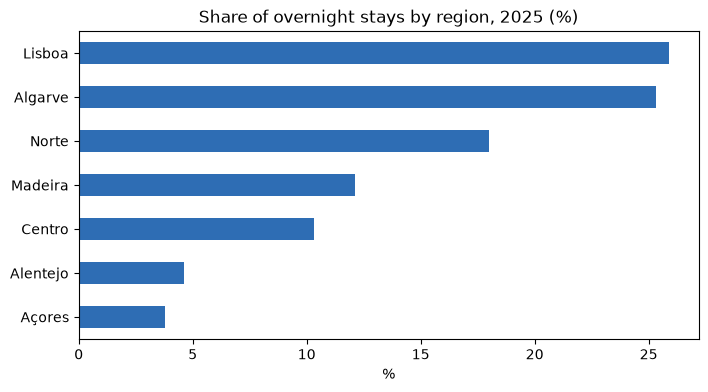

In [273]:
region_table["share %"].sort_values().plot(kind="barh", color=BLUE, figsize=(8, 4))
plt.title(f"Share of overnight stays by region, {YEAR} (%)")
plt.xlabel("%")
plt.ylabel("")
plt.show()

### 1.2 Are tourists concentrated in a few places?

Portugal has 308 municipalities. How much of the tourism goes to the **top 10**?

In [274]:
stays_mun = municipalities.set_index("municipality")["stays_2025"].dropna().sort_values(ascending=False)

top10_share = stays_mun.head(10).sum() / stays_mun.sum() * 100
top10_names = ", ".join(stays_mun.head(10).index)

print(f"The top 10 municipalities have {top10_share:.0f}% of all overnight stays")
print("Top 10:", top10_names)

The top 10 municipalities have 59% of all overnight stays
Top 10: Lisboa, Albufeira, Porto, Funchal, Loulé, Portimão, Lagos, Lagoa (Algarve), Ponta Delgada, Cascais


#### The top 10 municipalities

In [275]:
top10 = (municipalities.dropna(subset=["stays_2025"])
         .sort_values("stays_2025", ascending=False)
         .head(10)[["municipality", "region", "stays_2025"]])

top10["stays (millions)"] = (top10["stays_2025"] / 1_000_000).round(1)
top10["share %"] = (top10["stays_2025"] / stays_mun.sum() * 100).round(1)
top10.index = range(1, 11)   # rank 1 to 10

top10[["municipality", "region", "stays (millions)", "share %"]]

,municipality,region,stays (millions),share %
1,Lisboa,Lisboa,16.0,19.5
2,Albufeira,Algarve,7.5,9.1
3,Porto,Norte,6.6,8.1
4,Funchal,Madeira,6.4,7.8
5,Loulé,Algarve,2.9,3.5
6,Portimão,Algarve,2.8,3.4
7,Lagos,Algarve,1.8,2.2
8,Lagoa (Algarve),Algarve,1.8,2.1
9,Ponta Delgada,Açores,1.6,1.9
10,Cascais,Lisboa,1.5,1.8


6 municipalities (2% of all) have 50% of the overnight stays
39 municipalities (13% of all) have 80% of the overnight stays


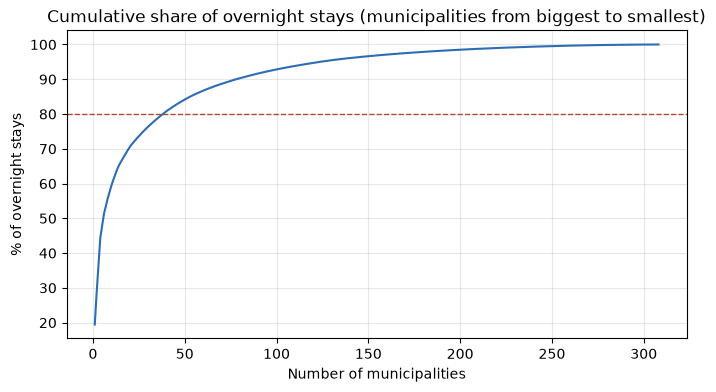

In [276]:
# Cumulative share: how many municipalities do we need to reach 50%, 80%...?
cumulative = stays_mun.cumsum() / stays_mun.sum() * 100

for target in [50, 80]:
    n = (cumulative < target).sum() + 1
    print(f"{n} municipalities ({n / len(stays_mun):.0%} of all) have {target}% of the overnight stays")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative.values, color=BLUE)
plt.axhline(80, color=RED, linestyle="--", linewidth=1)
plt.title("Cumulative share of overnight stays (municipalities from biggest to smallest)")
plt.xlabel("Number of municipalities")
plt.ylabel("% of overnight stays")
plt.grid(alpha=0.3)
plt.show()

💡 Tourism is **very concentrated**: a few municipalities get most tourists. Most of Portugal gets very few → room for *hidden gems* (Q5).

---
## 2. 📅 Q2 – When do they go?
### 2.1 Monthly profile of each region

To compare big and small regions, we use the **% of the year** that happens in each month (not the total number).

In [277]:
region_month = month_year.pivot_table(index="month_number", columns="region", values="overnight_stays", aggfunc="sum")
region_month_pct = region_month / region_month.sum() * 100   # each column sums to 100%

region_month_pct.index = MONTHS
region_month_pct.round(1)

region,Alentejo,Algarve,Açores,Centro,Lisboa,Madeira,Norte
Jan,3.8,2.7,3.2,4.7,5.4,6.4,4.5
Feb,4.3,3.7,4.0,5.0,5.9,6.7,5.1
Mar,5.7,5.5,6.2,6.7,7.8,7.9,6.8
Apr,8.0,8.8,8.7,8.5,8.8,8.5,8.7
May,9.0,9.7,10.3,9.1,9.5,9.0,9.7
Jun,10.3,11.4,11.2,9.0,9.1,9.1,9.4
Jul,12.5,13.9,13.7,11.0,10.0,10.1,10.7
Aug,15.8,15.6,14.7,14.3,10.8,10.4,12.9
Sep,11.4,11.4,11.6,10.2,9.6,9.2,10.4
Oct,8.6,9.9,8.6,8.8,9.6,9.1,9.3


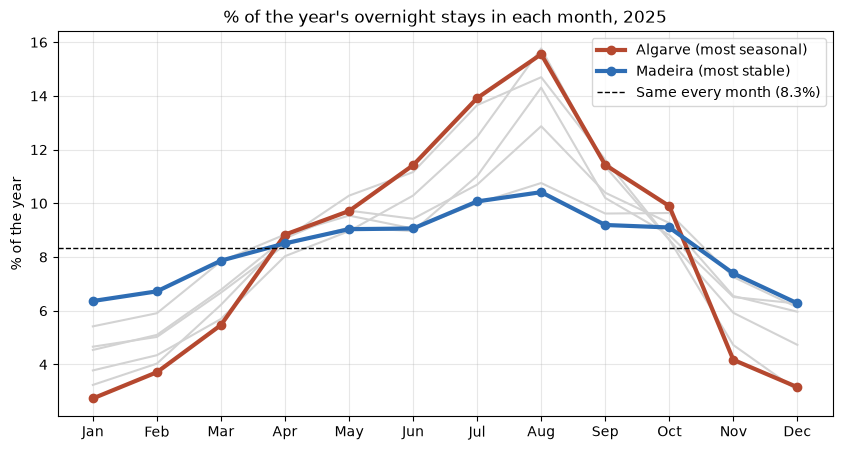

In [278]:
# All regions in light grey, the two extremes in colour
plt.figure(figsize=(10, 5))
for region in region_month_pct.columns:
    plt.plot(MONTHS, region_month_pct[region], color="lightgrey", linewidth=1.5)

plt.plot(MONTHS, region_month_pct["Algarve"], color=RED, linewidth=3, marker="o", label="Algarve (most seasonal)")
plt.plot(MONTHS, region_month_pct["Madeira"], color=BLUE, linewidth=3, marker="o", label="Madeira (most stable)")
plt.axhline(100 / 12, color="black", linestyle="--", linewidth=1, label="Same every month (8.3%)")

plt.title(f"% of the year's overnight stays in each month, {YEAR}")
plt.ylabel("% of the year")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 2.2 How seasonal is each region?

Two simple measures:
- **Summer share** = % of the year's stays that happen in **June–September**. If tourism was the same every month, it would be 4/12 = **33%**.
- **Peak ÷ low** = how many times bigger the best month is than the worst month.

In [279]:
summer = [6, 7, 8, 9]
summer_share_region = (region_month.loc[summer].sum() / region_month.sum() * 100).round(1)
peak_month = region_month.idxmax().map(lambda m: MONTHS[m - 1])
low_month = region_month.idxmin().map(lambda m: MONTHS[m - 1])

# How many times bigger is the best month than the worst month?
# 1 = the same all year · the bigger the number, the bigger the ups and downs
peak_vs_low = (region_month.max() / region_month.min()).round(1)

seasonality = pd.DataFrame({"summer share %": summer_share_region, "peak month": peak_month,
                            "low month": low_month, "peak ÷ low": peak_vs_low})
seasonality = seasonality.sort_values("peak ÷ low", ascending=False)
seasonality

,summer share %,peak month,low month,peak ÷ low
region,,,,
Algarve,52.3,Aug,Jan,5.7
Açores,51.1,Aug,Dec,4.9
Alentejo,49.9,Aug,Jan,4.2
Centro,44.5,Aug,Jan,3.1
Norte,43.4,Aug,Jan,2.8
Lisboa,39.4,Aug,Jan,2.0
Madeira,38.7,Aug,Dec,1.7


**Peak ÷ low** = stays in the best month ÷ stays in the worst month.
- **1** → the same every month
- **5** → the best month has 5 times more tourists than the worst month

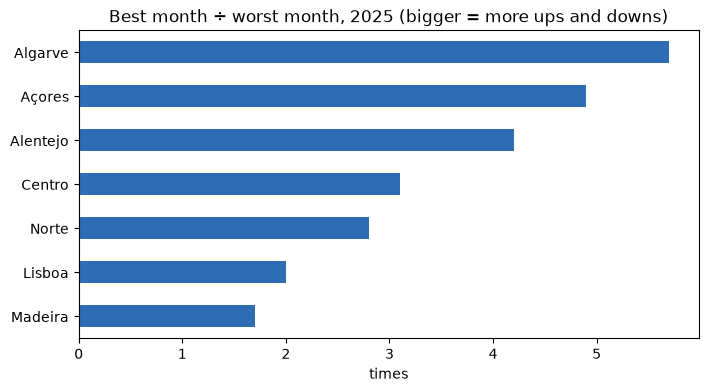

In [280]:
seasonality["peak ÷ low"].sort_values().plot(kind="barh", color=BLUE, figsize=(8, 4))
plt.title(f"Best month ÷ worst month, {YEAR} (bigger = more ups and downs)")
plt.xlabel("times")
plt.ylabel("")
plt.show()

💡 **August is the peak everywhere.** The **Algarve** has the biggest ups and downs (August has ~6 times more tourists than January). **Madeira** and **Lisboa** are the most stable all year (less than 2 times) → good for packages *out of summer*.

### 2.3 Hypothesis test 1 – Is seasonality different between regions?

We calculate the summer share **for each municipality** and compare the 7 regions.

- **H0:** the summer share is the same in all regions
- **H1:** at least one region is different

We use **Kruskal-Wallis** (like ANOVA, but it doesn't need normal data).

In [281]:
mun_month = month_year.pivot_table(index="municipality", columns="month_number", values="overnight_stays", aggfunc="sum")
mun_month = mun_month.dropna()   # keep municipalities with all 12 months

municipalities = municipalities.set_index("municipality")
municipalities["summer_share"] = mun_month[summer].sum(axis=1) / mun_month.sum(axis=1)
municipalities = municipalities.reset_index()

groups = [g["summer_share"].dropna() for _, g in municipalities.groupby("region")]
h_stat, p_value = stats.kruskal(*groups)

print(f"Kruskal-Wallis: H = {h_stat:.1f}, p-value = {p_value:.4f}")
print("Reject H0 → seasonality is different between regions" if p_value < 0.05 else "We can't reject H0")

Kruskal-Wallis: H = 60.3, p-value = 0.0000
Reject H0 → seasonality is different between regions


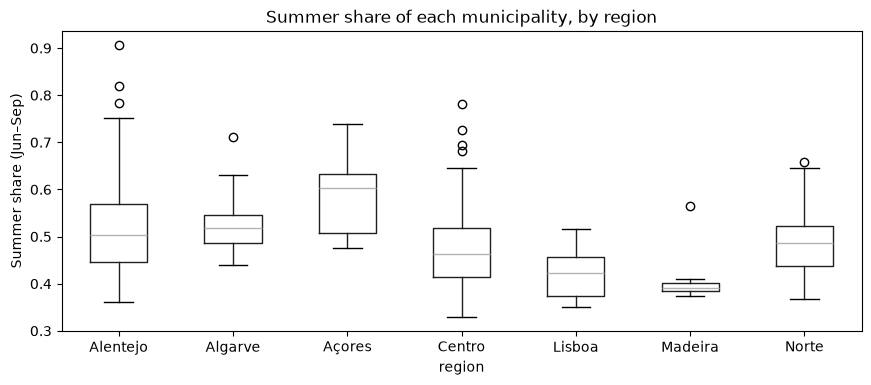

In [282]:
municipalities.boxplot(column="summer_share", by="region", figsize=(10, 4), grid=False)
plt.title("Summer share of each municipality, by region")
plt.suptitle("")
plt.ylabel("Summer share (Jun–Sep)")
plt.show()

### 2.4 Hypothesis test 2 – Are beach municipalities more seasonal?

We expect *yes*… but let's check!

- **H0:** municipalities **with** a Blue Flag beach have the same summer share as municipalities **without**
- **H1:** they are different

We use **Mann-Whitney U** (compares 2 groups, doesn't need normal data).

In [283]:
with_beach = municipalities[municipalities["n_beach"] > 0]["summer_share"].dropna()
without_beach = municipalities[municipalities["n_beach"] == 0]["summer_share"].dropna()

print(f"With beach:    median summer share = {with_beach.median():.1%}  ({len(with_beach)} municipalities)")
print(f"Without beach: median summer share = {without_beach.median():.1%}  ({len(without_beach)} municipalities)")

u_stat, p_value = stats.mannwhitneyu(with_beach, without_beach)
print(f"\nMann-Whitney U: p-value = {p_value:.3f}")
print("Reject H0 → they are different" if p_value < 0.05 else "We can't reject H0 → no significant difference")

With beach:    median summer share = 48.8%  (99 municipalities)
Without beach: median summer share = 48.1%  (200 municipalities)

Mann-Whitney U: p-value = 0.245
We can't reject H0 → no significant difference


Municipalities without beach are **as seasonal** as the ones with beach.
In August, many small inland towns are full too (holidays, emigrants coming home, festivals).
➡️ *Summer is not only for the beach*: countryside and nature packages can also sell in summer.

---
## 3. 🌍 Q3 – Who visits each region?
### 3.1 Portuguese vs foreign tourists

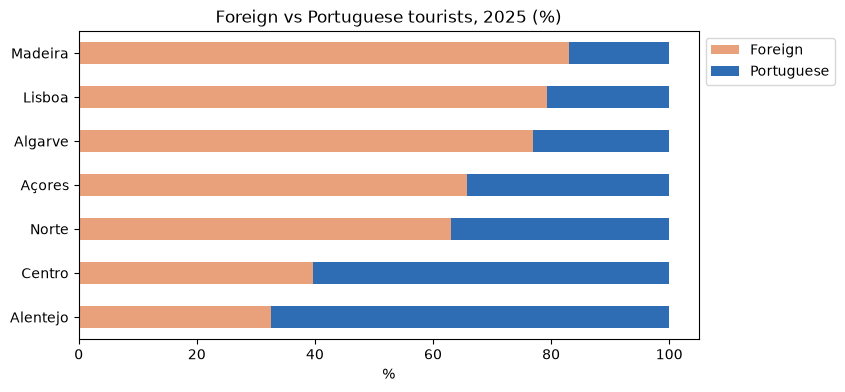

In [284]:
pt_vs_foreign = nat_year[nat_year["country"].isin(["Portugal", "Foreign countries"])].pivot_table(
    index="region", columns="country", values="overnight_stays", aggfunc="sum")
pt_vs_foreign = (pt_vs_foreign.div(pt_vs_foreign.sum(axis=1), axis=0) * 100).round(1)
pt_vs_foreign = pt_vs_foreign.sort_values("Foreign countries")

pt_vs_foreign.plot(kind="barh", stacked=True, color=[SAND, BLUE], figsize=(8, 4))
plt.title(f"Foreign vs Portuguese tourists, {YEAR} (%)")
plt.xlabel("%")
plt.ylabel("")
plt.legend(["Foreign", "Portuguese"], bbox_to_anchor=(1, 1))
plt.show()

### 3.2 Top 3 foreign countries in each region

In [285]:
foreign = nat_year[~nat_year["country"].isin(NOT_COUNTRIES)]
region_country = foreign.pivot_table(index="region", columns="country", values="overnight_stays", aggfunc="sum")

top3 = {}
for region in region_country.index:
    top3[region] = ", ".join(region_country.loc[region].sort_values(ascending=False).head(3).index)

pd.Series(top3, name="top 3 countries").to_frame()

,top 3 countries
Alentejo,"Spain, United States, Germany"
Algarve,"United Kingdom, Germany, Ireland"
Açores,"United States, Germany, Spain"
Centro,"Spain, France, United States"
Lisboa,"United States, United Kingdom, Spain"
Madeira,"Germany, United Kingdom, Poland"
Norte,"Spain, United States, France"


💡 The UK and Germany are in the top 3 almost everywhere because they are big markets. To know **where to sell each package**, we need a better measure ⬇️

### 3.3 Which region does each country *prefer*? (Preference index)

**Preference index** = (share of the country **in the region**) ÷ (share of the country **in Portugal**)

- **> 1** → this country likes this region **more than average** ✅ (sell there!)
- **= 1** → normal
- **< 1** → less than average

Example: if the Irish are 3% of tourists in Portugal but 7% in the Algarve → index = 2.3

In [286]:
share_in_region = region_country.div(region_country.sum(axis=1), axis=0)
share_in_portugal = region_country.sum() / region_country.values.sum()
preference = share_in_region / share_in_portugal

# Only countries with enough tourists (at least 500 000 stays in Portugal)
big_countries = region_country.sum()[region_country.sum() >= 500_000].index
preference = preference[big_countries]

preference.round(2)

country,Austria,Belgium,Brazil,Canada,China,Denmark,France,Germany,Ireland,Italy,Netherlands,Poland,Spain,Sweden,Switzerland,United Kingdom,United States
region,,,,,,,,,,,,,,,,,
Alentejo,1.15,1.54,1.47,1.00,1.49,0.69,0.87,1.05,0.27,1.21,1.16,0.43,2.05,0.71,1.51,0.42,1.27
Algarve,0.70,1.05,0.27,0.83,0.27,0.72,0.78,1.01,2.56,0.45,1.49,0.51,0.55,1.17,0.84,1.99,0.39
Açores,1.91,1.24,0.18,2.06,0.24,1.77,0.99,1.45,0.11,1.26,1.08,0.97,1.30,0.51,2.06,0.21,1.72
Centro,0.84,0.99,1.69,0.74,0.98,0.58,1.28,0.62,0.30,1.45,0.72,1.59,2.63,0.63,1.05,0.27,0.85
Lisboa,0.97,0.87,1.87,1.40,2.02,0.81,0.96,0.66,0.44,1.58,0.66,0.62,0.90,1.03,0.94,0.47,1.74
Madeira,1.56,1.12,0.09,0.35,0.08,2.12,1.00,2.05,0.35,0.43,1.11,2.93,0.26,1.28,0.99,1.27,0.25
Norte,0.90,0.92,1.46,1.05,1.45,0.82,1.38,0.65,0.36,1.23,0.69,0.65,1.86,0.66,1.07,0.47,1.31


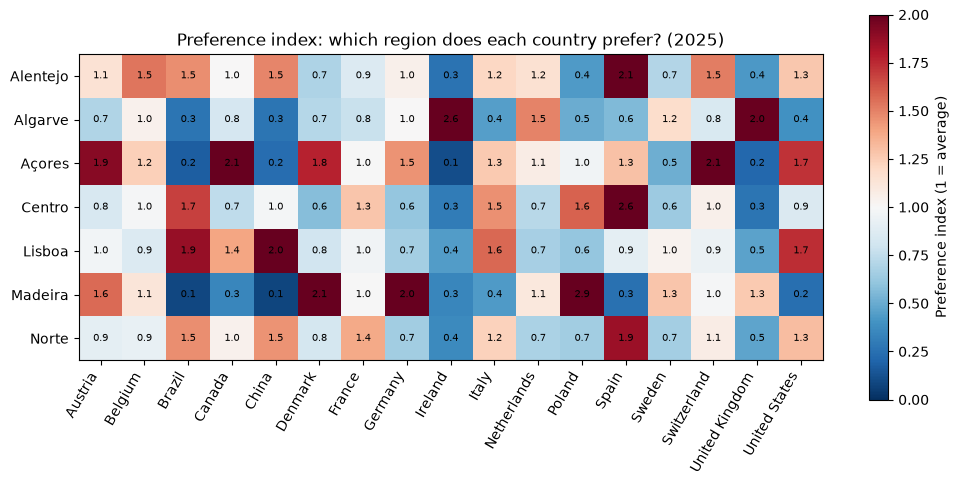

In [287]:
fig, ax = plt.subplots(figsize=(12, 5))
image = ax.imshow(preference.values, cmap="RdBu_r", vmin=0, vmax=2)
ax.set_xticks(range(len(preference.columns)))
ax.set_xticklabels(preference.columns, rotation=60, ha="right")
ax.set_yticks(range(len(preference.index)))
ax.set_yticklabels(preference.index)
for i in range(preference.shape[0]):
    for j in range(preference.shape[1]):
        ax.text(j, i, f"{preference.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(image, label="Preference index (1 = average)")
plt.title(f"Preference index: which region does each country prefer? ({YEAR})")
plt.show()

In [288]:
# Top 4 countries that prefer each region → where to sell
best_markets = {}
for region in preference.index:
    best = preference.loc[region].sort_values(ascending=False).head(4)
    best_markets[region] = ", ".join(f"{c} ({v:.1f})" for c, v in best.items())

pd.Series(best_markets, name="sell to (preference index)").to_frame()

,sell to (preference index)
Alentejo,"Spain (2.1), Belgium (1.5), Switzerland (1.5),..."
Algarve,"Ireland (2.6), United Kingdom (2.0), Netherlan..."
Açores,"Switzerland (2.1), Canada (2.1), Austria (1.9)..."
Centro,"Spain (2.6), Brazil (1.7), Poland (1.6), Italy..."
Lisboa,"China (2.0), Brazil (1.9), United States (1.7)..."
Madeira,"Poland (2.9), Denmark (2.1), Germany (2.0), Au..."
Norte,"Spain (1.9), Brazil (1.5), China (1.5), France..."


### 3.4 Hypothesis test 3 – Does the country of origin depend on the region?

- **H0:** the mix of countries is the same in every region (country and region are independent)
- **H1:** the mix of countries depends on the region

We use the **Chi-square test of independence**.

⚠️ With millions of stays, almost any difference is "significant". So we also look at **Cramér's V**, which says **how strong** the relation is (0 = none, 1 = perfect).

In [289]:
table = region_country[big_countries].fillna(0)
chi2, p_value, dof, expected = stats.chi2_contingency(table)

n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

print(f"Chi-square p-value = {p_value:.4f}")
print(f"Cramér's V = {cramers_v:.2f}")
print("→ Country and region are related" if p_value < 0.05 else "→ No relation")

Chi-square p-value = 0.0000
Cramér's V = 0.24
→ Country and region are related


💡 Rule of thumb for Cramér's V: 0.1 = small, 0.3 = medium, 0.5 = large.

---
## 4. 🏖️🏛️🌲🏡 Q4 – Beach, city, countryside or nature?
### 4.1 What does each region offer?

Number of places of each category, as **% of the region's places** (to compare regions of different sizes).

In [290]:
offer = pd.crosstab(places["region"], places["category"])
offer_pct = (offer.div(offer.sum(axis=1), axis=0) * 100).round(1)
offer_pct

category,beach,countryside,culture,nature,viewpoint
region,,,,,
Alentejo,3.9,0.0,88.9,1.2,6.0
Algarve,25.0,0.0,58.7,1.7,14.5
Açores,6.4,0.0,32.3,21.8,39.4
Centro,5.0,2.3,76.1,1.3,15.4
Lisboa,3.2,0.0,83.1,2.1,11.6
Madeira,3.7,0.0,24.1,8.0,64.2
Norte,3.7,0.0,78.2,1.0,17.1


#### The specialty of each region

With counts only, culture wins everywhere (it is the biggest category).
So we use the **same idea as the preference index** (3.3):

**Specialty index** = % of the category **in the region** ÷ % of the category **in Portugal**

- **> 1** → the region has more of this than the average
- The category with the **highest index** is the region's **specialty**

(Food is not here: every package has its own typical food, in notebook 03.)

In [291]:
# What a tourist goes to see: beaches, culture, nature, villages, viewpoints
sights = offer
sights_pct = sights.div(sights.sum(axis=1), axis=0) * 100   # % of each category in the region
country_pct = sights.sum() / sights.values.sum() * 100       # % of each category in Portugal
specialty_index = (sights_pct / country_pct).round(2)

specialty = pd.DataFrame({
    "specialty": specialty_index.idxmax(axis=1),
    "index": specialty_index.max(axis=1),
}).sort_values("index", ascending=False)
specialty

,specialty,index
region,,
Açores,nature,5.97
Algarve,beach,4.84
Centro,countryside,4.39
Madeira,viewpoint,3.32
Alentejo,culture,1.25
Lisboa,culture,1.17
Norte,culture,1.10


### 4.2 Hypothesis test 4 – Do places attract tourists?

Do municipalities with **more places** have **more overnight stays**?

We use the **Spearman correlation** (works with ranks, OK with very big and very small municipalities).
- **H0:** no correlation (ρ = 0)
- **H1:** there is a correlation

In [292]:
results = []
for column in ["n_beach", "n_culture", "n_viewpoint", "n_nature", "n_countryside"]:
    rho, p_value = stats.spearmanr(municipalities[column], municipalities["stays_2025"], nan_policy="omit")
    results.append({"type of place": column.replace("n_", "").replace("countryside", "historic villages"), "Spearman ρ": round(rho, 2), "p-value": round(p_value, 4)})

pd.DataFrame(results).sort_values("Spearman ρ", ascending=False)

,type of place,Spearman ρ,p-value
0,beach,0.53,0.0000
1,culture,0.44,0.0000
2,viewpoint,0.39,0.0000
3,nature,0.39,0.0000
4,historic villages,-0.13,0.0223


💡 Almost all correlations are **positive**: municipalities with more places get more tourists.
- **Historic villages** are the only **negative** one (-0.13): they are in places with **few tourists**.

The correlations are far from perfect → some municipalities have **a lot to offer and few tourists**. Those are our **hidden gems** ⬇️

---
## 5. 💎 Q5 – Hidden gems

**Our rule:** a municipality is a *hidden gem* if it is
1. in the **top 25%** for quality markers (Blue Flag, classified monuments, protected areas, historic villages…), **and**
2. in the **bottom 50%** for overnight stays

In [293]:
data = municipalities.dropna(subset=["stays_2025"]).copy()

quality_limit = data["n_quality_markers"].quantile(0.75)
stays_limit = data["stays_2025"].median()
print(f"Top 25% quality markers: at least {quality_limit:.0f}")
print(f"Bottom 50% overnight stays: less than {stays_limit:,.0f}")

data["hidden_gem"] = (data["n_quality_markers"] >= quality_limit) & (data["stays_2025"] < stays_limit)

gems = data[data["hidden_gem"]].sort_values("n_quality_markers", ascending=False)
gems[["municipality", "region", "stays_2025", "n_quality_markers", "n_culture", "n_nature",
      "n_beach", "n_countryside"]]

Top 25% quality markers: at least 16
Bottom 50% overnight stays: less than 38,860


,municipality,region,stays_2025,n_quality_markers,n_culture,n_nature,n_beach,n_countryside
82,Vila Nova de Foz Côa,Norte,13183.0,32,42,0,0,0
258,Marco de Canaveses,Norte,27592.0,23,27,1,0,0
250,Moura,Alentejo,30942.0,23,28,0,1,0
33,Nisa,Alentejo,24160.0,22,25,1,0,0
228,Mangualde,Centro,28799.0,19,21,0,0,0
38,Borba,Alentejo,2242.0,18,20,0,0,0
50,Santa Cruz das Flores,Açores,20995.0,18,9,15,0,0
81,Torre de Moncorvo,Norte,16071.0,18,27,0,0,0
195,Montemor-o-Velho,Centro,10166.0,17,18,1,1,0
243,Alvito,Alentejo,8073.0,16,19,0,0,0


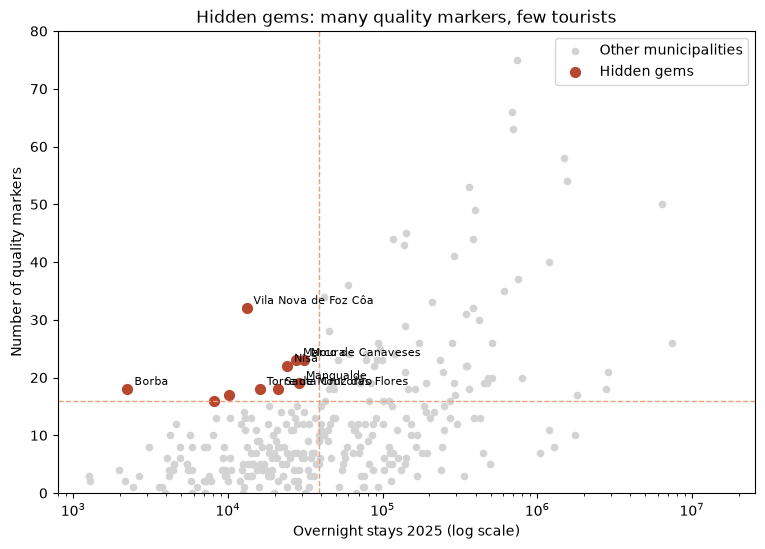

In [294]:
plt.figure(figsize=(9, 6))
normal = data[~data["hidden_gem"]]
plt.scatter(normal["stays_2025"], normal["n_quality_markers"], color="lightgrey", s=20, label="Other municipalities")
plt.scatter(gems["stays_2025"], gems["n_quality_markers"], color=RED, s=50, label="Hidden gems")

for _, row in gems.head(8).iterrows():
    plt.annotate(row["municipality"], (row["stays_2025"], row["n_quality_markers"]), fontsize=8,
                 xytext=(5, 3), textcoords="offset points")

plt.xscale("log")   # log scale: from 1 000 to 16 million stays
plt.ylim(0, 80)     # zoom in: Lisboa and Porto (more than 150 markers) are outside the chart
plt.axhline(quality_limit, color=SAND, linestyle="--", linewidth=1)
plt.axvline(stays_limit, color=SAND, linestyle="--", linewidth=1)
plt.title("Hidden gems: many quality markers, few tourists")
plt.xlabel(f"Overnight stays {YEAR} (log scale)")
plt.ylabel("Number of quality markers")
plt.legend()
plt.show()

In [295]:
# What makes each gem special? Its quality places
gem_places = places[(places["municipality"].isin(gems["municipality"])) & (places["quality_marker"] == True)]
pd.crosstab(gem_places["municipality"], gem_places["subcategory"]).loc[gems["municipality"]]

subcategory,National Monument,Public Interest,UNESCO World Heritage,natural area,river
municipality,,,,,
Vila Nova de Foz Côa,2,9,21,0,0
Marco de Canaveses,7,15,0,1,0
Moura,2,20,0,0,1
Nisa,3,18,0,1,0
Mangualde,3,16,0,0,0
Borba,3,15,0,0,0
Santa Cruz das Flores,0,3,0,15,0
Torre de Moncorvo,3,13,2,0,0
Montemor-o-Velho,3,12,0,1,1


---
## 6. 💾 Save files for Tableau

In [296]:
# Region x month (% of the year)
region_month_long = region_month_pct.reset_index().melt(id_vars="index", var_name="region", value_name="pct_of_year")
region_month_long = region_month_long.rename(columns={"index": "month"})
region_month_long["month_number"] = region_month_long["month"].map(lambda m: MONTHS.index(m) + 1)   # 1 = Jan … 12 = Dec (to sort in Tableau)
region_month_long.to_csv(CLEAN + "tableau_region_month.csv", index=False)

# Region x country: stays + preference index
pref_long = preference.reset_index().melt(id_vars="region", var_name="country", value_name="preference_index")
stays_long = region_country.reset_index().melt(id_vars="region", var_name="country", value_name="overnight_stays")
pref_long.merge(stays_long, on=["region", "country"]).to_csv(CLEAN + "tableau_region_country.csv", index=False)

# Municipalities with summer share, hidden gem flag and coordinates (for the map)
# The last 4 characters of the INE code are the "DICO" code, also used by Wikidata
coordinates = pd.read_csv(RAW + "municipality_coordinates.csv", dtype={"dico_code": str})
data["dico_code"] = data["municipality_code"].str[-4:]
data = data.merge(coordinates[["dico_code", "latitude", "longitude"]], on="dico_code", how="left")
print("Municipalities without coordinates:", data["latitude"].isna().sum())
data.to_csv(CLEAN + "tableau_municipalities.csv", index=False)

# Concentration curve: municipalities from most to least visited + cumulative % of stays
concentration = pd.DataFrame({"municipality": stays_mun.index, "stays_2025": stays_mun.values})
concentration["rank"] = range(1, len(concentration) + 1)
concentration["cumulative_pct"] = (cumulative.values).round(2)
concentration.to_csv(CLEAN + "tableau_concentration.csv", index=False)


print("Saved ✅")

Municipalities without coordinates: 0
Saved ✅


### 🗺️ Filled map: each municipality gets a colour

Instead of bubbles, we paint each municipality.
- The **shapes** of the municipalities come from the official map of Portugal (CAOP, Direção-Geral do Território).
- We join them to our numbers with the **DICO code** (the same code we used for the coordinates).
- Lisboa has ~16 million stays and many small municipalities have less than 50 000. With a normal colour scale, Lisboa would be dark and all the rest the same light colour. So we use **5 groups**.

In [297]:
import json

# 1. The shapes of the 308 municipalities (GeoJSON = a map file)
with open(RAW + "municipality_boundaries_caop.geojson", encoding="utf-8-sig") as f:
    boundaries = json.load(f)

# 2. Five groups of overnight stays
bins = [0, 50_000, 200_000, 1_000_000, 5_000_000, float("inf")]
labels = ["1. Less than 50k", "2. 50k – 200k", "3. 200k – 1M", "4. 1M – 5M", "5. More than 5M"]
data["stays_group"] = pd.cut(data["stays_2025"], bins=bins, labels=labels, right=False)
print(data["stays_group"].value_counts().sort_index())

# 3. Put our numbers inside each shape (joined by the DICO code)
info = data.set_index("dico_code")

def round_coordinates(c):
    """Keeps 4 decimals (about 10 metres): the file gets much smaller"""
    if isinstance(c[0], list):
        return [round_coordinates(x) for x in c]
    return [round(x, 4) for x in c]

for feature in boundaries["features"]:
    row = info.loc[feature["properties"]["DICO"]]
    feature["properties"] = {
        "municipality": row["municipality"],
        "region": row["region"],
        "stays_2025": None if pd.isna(row["stays_2025"]) else float(row["stays_2025"]),
        "stays_group": "No data" if pd.isna(row["stays_group"]) else row["stays_group"],
        "hidden_gem": bool(row["hidden_gem"]),
    }
    feature["geometry"]["coordinates"] = round_coordinates(feature["geometry"]["coordinates"])

with open(CLEAN + "tableau_map.geojson", "w", encoding="utf-8") as f:
    json.dump(boundaries, f, ensure_ascii=False)

print("Municipalities on the map:", len(boundaries["features"]))

stays_group
1. Less than 50k    173
2. 50k – 200k        79
3. 200k – 1M         42
4. 1M – 5M           10
5. More than 5M       4
Name: count, dtype: int64
Municipalities on the map: 308


### 🗺️ Region map with the specialty of each region

The municipality shapes have a line around **every** municipality, so we can't see where a region ends.
So for this map we use the **shapes of the 7 regions** (NUTS II, from Eurostat) and put the specialty inside.
(For the islands we keep the municipality shapes: Eurostat's file cuts part of the Açores.)

In [298]:
with open(RAW + "nuts2_regions_portugal.geojson", encoding="utf-8") as f:
    regions_map = json.load(f)

# Eurostat code -> our region names
NUTS_NAMES = {"PT11": "Norte", "PT15": "Algarve", "PT16": "Centro", "PT17": "Lisboa",
              "PT18": "Alentejo", "PT20": "Açores", "PT30": "Madeira"}

# A symbol and a name for each specialty
SYMBOLS = {"beach": "🏖️ Beach", "culture": "🏛️ Culture", "countryside": "🏡 Villages",
           "nature": "🌲 Nature", "viewpoint": "🔭 Viewpoints"}

# Eurostat's file cuts the far-away Açores islands,
# so for the 2 island regions we use the municipality shapes (CAOP) from the map above
island_shapes = {"Açores": [], "Madeira": []}
for feature in boundaries["features"]:
    region = feature["properties"]["region"]
    if region in island_shapes:
        geometry = feature["geometry"]
        island_shapes[region] += [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]

for feature in regions_map["features"]:
    region = NUTS_NAMES[feature["properties"]["id"]]
    if region in island_shapes:
        feature["geometry"] = {"type": "MultiPolygon", "coordinates": island_shapes[region]}
    row = specialty.loc[region]
    feature["properties"] = {
        "region": region,
        "specialty": row["specialty"],
        "index": float(row["index"]),
        "label": f"{SYMBOLS[row['specialty']]} {row['index']:.1f}×",
    }

with open(CLEAN + "tableau_regions.geojson", "w", encoding="utf-8") as f:
    json.dump(regions_map, f, ensure_ascii=False)

print("Regions on the map:", len(regions_map["features"]))

Regions on the map: 7


---
## ✅ Main findings

| Question | Answer |
|---|---|
| **Q1 Where?** | Lisboa and the Algarve have about **half** of all stays. Only **6 of 308** municipalities have 50% of all stays |
| **Q2 When?** | August is the peak everywhere. Best month ÷ worst month: Algarve **5.7×**, Madeira only **1.7×**. Beach municipalities are **not** more seasonal than the others (test 2) |
| **Q3 Who?** | The mix of countries depends on the region (test 3). Each region has its own "best markets" (preference index) |
| **Q4 What?** | Each region has a specialty: Açores nature **6.0×**, Algarve beach **4.8×**, Centro villages **4.4×**, Madeira viewpoints **3.3×**. More places → more tourists (test 4) |
| **Q5 Gems** | **10 municipalities** with a lot of quality and few tourists (e.g. Vila Nova de Foz Côa) |

**Next (notebook 03):** we put these answers together into **one travel package per region**.